# 02 — Explore the open satellite data over Zankalon (multispectral + hyperspectral)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammed2008H/Reclaim-Front-End-/blob/main/notebooks/02_Zankalon_Open_Data_Explorer.ipynb)

**Project RECLAIM · Theme: Precision Agriculture & Crop Intelligence · Study area: Zankalon, Sharqiya, Egypt**

### What this notebook does
It answers three questions a reviewer will ask first:

1. **Where does the data come from, and can I get it myself?** It queries two *public* catalogues live — no account, no password, no file upload:
   * **Sentinel-2** (multispectral, 10–20 m) from the Element 84 *Earth Search* catalogue, and
   * **Planet Tanager** (hyperspectral, 426 narrow bands, ~30 m) from Planet's open STAC catalogue (CC BY 4.0).
2. **What does the imagery look like?** It reads *only the pixels inside our study rectangle* and shows a true-colour picture and a vegetation (NDVI) map **right here in the notebook**, for a winter and a summer date.
3. **What does hyperspectral add?** It looks at a hyperspectral scene, plots the full reflectance curve of vegetation vs. bare soil, maps the *red-edge position*, and compares that to what Sentinel-2's few bands can capture.

### How to read the output
* Pictures appear **inline under each code cell** (scroll down after a cell finishes).
* Every picture is also saved as a PNG: open the **folder icon in Colab's left sidebar → `results/explorer/`** (or run the last cell to download a ZIP).
* Runtime: ~2 min for Sentinel-2; the optional hyperspectral demo downloads one scene (**about 1–5 GB**, ~2–10 min on Colab). Set `RUN_HYPERSPECTRAL_DEMO = False` in step 2 to skip it.
* CPU is enough. No GPU. No API keys.

### Honest scope
* The **screening result** (98 investigation candidates) comes from notebook 04 and uses Sentinel-2 only. This notebook is *exploration and evidence of data access* — it does not change that result.
* Planet's open Tanager scenes are a limited sample. **Step 5 checks whether any of them cover Zankalon.** If none do, the hyperspectral part is labelled a **method demonstration on a scene elsewhere** — it is *not* a Zankalon measurement. Real Zankalon hyperspectral data would come from EnMAP (notebook 03, needs a free DLR account).

## 1. Install the tools
Takes about a minute. If Colab asks you to restart the runtime, do so, then continue from step 2.

In [1]:
#@title 1. Install data-access tools
%pip -q install pystac-client==0.9.0 rasterio==1.4.4 h5py==3.16.0   # requests is preinstalled; see requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 2. Settings and helper functions
**Study area** is the same rectangle used by the whole project: `[west, south, east, north] = [31.41, 30.56, 31.46, 30.60]` (about 4.7 km × 4.4 km). It is a pilot rectangle, **not** an official farm or irrigation boundary.

You normally do not need to change anything. The helper functions are pasted in this cell so the notebook works on its own in Colab, without cloning the repository.

In [2]:
#@title 2. Settings and helper functions
from pathlib import Path
import json, math, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests, rasterio
from rasterio.enums import Resampling
from rasterio.warp import transform_bounds
warnings.filterwarnings("ignore", category=rasterio.errors.NotGeoreferencedWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)   # all-NaN slices are expected where pixels are masked
np.random.seed(42)

# ---------------- settings you may change ----------------
BBOX = [31.41, 30.56, 31.46, 30.60]       # west, south, east, north (WGS84)
CATALOG_URL   = "https://earth-search.aws.element84.com/v1"
S2_COLLECTION = "sentinel-2-c1-l2a"        # Sentinel-2 Level-2A (surface reflectance)
YEAR          = 2024                       # year searched for the best scene of each month
CLOUD_LIMIT   = 20                         # max % cloud over the whole 110 km tile
MIN_CLEAR_FRACTION = 0.80                  # a scene is shown only if >=80% of OUR rectangle is clear (SCL 4/5)
SHOW_MONTHS   = ["2024-02", "2024-07"]     # one winter-crop and one summer-crop month
RUN_HYPERSPECTRAL_DEMO = True              # False = skip the 1-5 GB hyperspectral download
DEMO_COLLECTION = "agriculture"            # Tanager collection used if nothing covers Zankalon
DEMO_ITEM_ID    = None                     # or paste a specific Tanager scene ID
# ----------------------------------------------------------

# Where files are saved: <repo>/results/explorer if the repo is present, else ./results/explorer
cwd = Path.cwd()
ROOT = next((p for p in [cwd, cwd.parent] if (p / "README.md").exists() and (p / "notebooks").is_dir()), cwd)
OUT = ROOT / "results" / "explorer"
CACHE = ROOT / "work" / "tanager_cache"          # 'work/' is git-ignored (big files stay out of GitHub)
OUT.mkdir(parents=True, exist_ok=True); CACHE.mkdir(parents=True, exist_ok=True)
GDAL_OPTS = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_CONNECTTIMEOUT="20", GDAL_HTTP_TIMEOUT="90")

STATUS = {"aoi_bbox_wgs84": BBOX, "aoi_note": "Zankalon pilot rectangle; not an official farm or irrigation boundary",
          "sentinel2": {}, "tanager": {}}

from pathlib import Path
import numpy as np
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import transform_bounds

def read_aoi(href, bbox_wgs84, out_shape=None, resampling=Resampling.bilinear):
    """Read only the pixels inside the AOI from a (cloud-optimised) GeoTIFF.
    Returns (array, scale, offset) where array is float32 with NaN for nodata."""
    with rasterio.open(href) as src:
        left, bottom, right, top = transform_bounds("EPSG:4326", src.crs, *bbox_wgs84)
        win = src.window(left, bottom, right, top).round_offsets().round_lengths()
        data = src.read(1, window=win, out_shape=out_shape, resampling=resampling,
                        boundless=True, fill_value=0).astype("float32")
        nodata = src.nodata
        if nodata is not None:
            data[data == nodata] = np.nan
    return data

def to_reflectance(dn, scale=0.0001, offset=-0.1):
    """Digital numbers -> surface reflectance. Zero DN = no data."""
    out = dn * scale + offset
    out[dn == 0] = np.nan
    return np.clip(out, 0, 1.2)

def asset_scale_offset(item, asset_key, default=(0.0001, -0.1)):
    """Use the STAC raster:bands scale/offset when present (never guess silently)."""
    try:
        rb = item.assets[asset_key].extra_fields.get("raster:bands", [{}])[0]
        return float(rb.get("scale", default[0])), float(rb.get("offset", default[1]))
    except Exception:
        return default

def stretch(rgb, lo=2, hi=98):
    out = np.zeros_like(rgb)
    for i in range(3):
        band = rgb[..., i]
        a, b = np.nanpercentile(band, [lo, hi])
        out[..., i] = np.clip((band - a) / max(b - a, 1e-6), 0, 1)
    return np.nan_to_num(out)

def ndvi(nir, red):
    with np.errstate(divide="ignore", invalid="ignore"):
        return (nir - red) / (nir + red)

CLEAR_SCL = (4, 5)          # vegetation, not-vegetated (bare soil)

import json, math, requests
import numpy as np

ROOT_CATALOG = "https://www.planet.com/data/stac/tanager-core-imagery/catalog.json"

def get_json(url, timeout=60):
    r = requests.get(url, timeout=timeout)
    r.raise_for_status()
    return r.json()

def bbox_distance_deg(a, b):
    """0 if the two [W,S,E,N] boxes overlap, else the gap in degrees (planar approximation)."""
    dx = max(a[0] - b[2], b[0] - a[2], 0)
    dy = max(a[1] - b[3], b[1] - a[3], 0)
    return math.hypot(dx, dy)

def collection_boxes(collection_json):
    """extent.spatial.bbox[0] is the union; the rest are per-scene boxes."""
    return collection_json["extent"]["spatial"]["bbox"][1:]

def item_links(collection_json):
    return [l["href"] for l in collection_json["links"] if l.get("rel") == "item"]

def wavelengths_nm(asset):
    """Centre wavelengths (nm) from STAC band metadata (stored in micrometres)."""
    return np.array([b["eo:center_wavelength"] * 1000.0
                     for b in asset.get("bands", []) if "eo:center_wavelength" in b])

def pick_sr_asset(assets):
    """Find the surface-reflectance HDF5 asset without hard-coding a key."""
    ranked = []
    for k, a in assets.items():
        name = k.lower()
        score = (("sr" in name.split("_")) or "surface" in name or "reflectance" in name) * 2 \
                + ("hdf" in name) + ("ortho" in name) * 0.5
        if score >= 3 and len(wavelengths_nm(a)) > 100:
            ranked.append((score, k))
    return sorted(ranked, reverse=True)[0][1] if ranked else None

def find_datasets(h5file):
    """Return {lowercase leaf name: dataset path} for every dataset in the file."""
    found = {}
    def visit(name, obj):
        if hasattr(obj, "shape"):
            found[name.split("/")[-1].lower()] = name
    h5file.visititems(visit)
    return found

def cube_axes(shape, n_wl):
    """Which axis is spectral? Returns (band_axis, row_axis, col_axis)."""
    cand = [i for i, s in enumerate(shape) if s == n_wl]
    if len(shape) != 3 or not cand:
        raise ValueError(f"Cannot find a {n_wl}-band axis in cube shape {shape}")
    b = cand[0]
    r, c = [i for i in range(3) if i != b]
    return b, r, c

def read_band_range(ds, band_axis, i0, i1):
    """Read bands i0:i1 and return array ordered (band, row, col) as float32 with NaN for nodata."""
    sl = [slice(None)] * 3
    sl[band_axis] = slice(i0, i1)
    arr = ds[tuple(sl)].astype("float32")
    arr = np.moveaxis(arr, band_axis, 0)
    sf = ds.attrs.get("scale_factor"); ao = ds.attrs.get("add_offset")
    if sf is not None: arr = arr * float(np.squeeze(sf))
    if ao is not None: arr = arr + float(np.squeeze(ao))
    arr[(arr <= -9000) | ~np.isfinite(arr)] = np.nan
    return arr

def red_edge_position(wl, spec_cube, good=None, lo=670, hi=780):
    """Wavelength (nm) of the steepest rise in reflectance between lo and hi.
    spec_cube: (band,row,col); good = boolean mask of usable bands.
    Descriptive only - not a chlorophyll estimate. Resolution = band spacing (~5 nm)."""
    m = (wl >= lo) & (wl <= hi)
    if good is not None: m &= good
    w, s = wl[m], spec_cube[m]
    d = np.diff(s, axis=0) / np.diff(w)[:, None, None]
    mid = (w[:-1] + w[1:]) / 2
    idx = np.nanargmax(np.where(np.isfinite(d), d, -np.inf), axis=0)
    rep = mid[idx].astype("float32")
    rep[~np.isfinite(s).all(axis=0)] = np.nan
    return rep

# Approximate Sentinel-2 band centres / widths (nm) used to "simulate" S2 from hyperspectral
S2_BANDS = {"B02": (490, 65), "B03": (560, 35), "B04": (665, 30), "B05": (705, 15),
            "B06": (740, 15), "B07": (783, 20), "B08": (842, 115), "B8A": (865, 20),
            "B11": (1610, 90), "B12": (2190, 180)}

def simulate_band(wl, cube, centre, width, good=None):
    """Average the usable narrow bands inside a Sentinel-2 band window (box-car, not the true response curve)."""
    m = (wl >= centre - width / 2) & (wl <= centre + width / 2)
    if good is not None: m &= good
    if not m.any():
        m = np.abs(wl - centre) == np.abs(wl - centre).min()
    return np.nanmean(cube[m], axis=0)

def usable_bands(ds, wl):
    """Bands safe to use: the file's own 'good_wavelengths' flag when present, otherwise the
    standard water-vapour windows (1350-1450 and 1800-1950 nm) are excluded."""
    g = ds.attrs.get("good_wavelengths")
    if g is not None and len(np.ravel(g)) == len(wl):
        return np.ravel(g).astype(bool)
    return ~(((wl >= 1350) & (wl <= 1450)) | ((wl >= 1800) & (wl <= 1950)))

def band_gaps(wl, good):
    """Contiguous wavelength ranges of unusable bands, for printing."""
    gaps, start = [], None
    for i, ok in enumerate(good):
        if not ok and start is None: start = wl[i]
        if ok and start is not None: gaps.append((start, wl[i - 1])); start = None
    if start is not None: gaps.append((start, wl[-1]))
    return gaps

def norm_diff(a, b):
    with np.errstate(divide="ignore", invalid="ignore"):
        return (a - b) / (a + b)

print("Study area (W,S,E,N):", BBOX)
print("Outputs will be saved in:", OUT)

Study area (W,S,E,N): [31.41, 30.56, 31.46, 30.6]
Outputs will be saved in: results/explorer


## 3. Search Sentinel-2 live for Zankalon
This sends a **metadata query** (no images are downloaded yet) to the public Earth Search catalogue: *"give me every Sentinel-2 L2A scene over this rectangle in the chosen year with low cloud cover."*

Cloud % here is for the whole 110 km × 110 km tile, not for our small rectangle; step 4 checks the rectangle itself.

pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


59 scenes with tile cloud < 20% in 2024. Best scene per month:


,month,scene_id,acquired_utc,tile_cloud_%
0,2024-01,S2B_T36RUU_20240113T083256_L2A,2024-01-13 08:41,0.00
1,2024-02,S2A_T36RUU_20240217T083256_L2A,2024-02-17 08:41,5.57
2,2024-03,S2A_T36RUU_20240308T083259_L2A,2024-03-08 08:41,8.30
3,2024-04,S2B_T36RUU_20240402T083858_L2A,2024-04-02 08:41,0.00
4,2024-05,S2A_T36RUU_20240517T083926_L2A,2024-05-17 08:41,0.00
5,2024-06,S2B_T36RUU_20240601T083907_L2A,2024-06-01 08:41,0.00
6,2024-07,S2A_T36RUU_20240716T083926_L2A,2024-07-16 08:41,0.00
7,2024-08,S2B_T36RUU_20240810T083502_L2A,2024-08-10 08:41,0.00
8,2024-09,S2B_T36RUU_20240919T083402_L2A,2024-09-19 08:41,0.00
9,2024-10,S2B_T36RUU_20241009T083250_L2A,2024-10-09 08:41,0.00


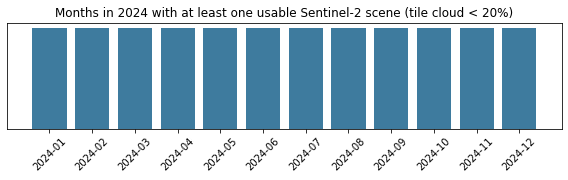

In [3]:
#@title 3. Query the Sentinel-2 catalogue
from pystac_client import Client

try:
    catalog = Client.open(CATALOG_URL)
    search = catalog.search(collections=[S2_COLLECTION], bbox=BBOX,
                            datetime=f"{YEAR}-01-01/{YEAR}-12-31",
                            query={"eo:cloud_cover": {"lt": CLOUD_LIMIT}}, max_items=500)
    items = list(search.items())
except Exception as e:
    items = []
    STATUS["sentinel2"] = {"catalog": CATALOG_URL, "collection": S2_COLLECTION, "year": YEAR,
                           "scenes_found": 0, "search_error": f"{type(e).__name__}: {e}"}
    print("SEARCH FAILED - Sentinel-2 catalogue request failed:", type(e).__name__, e)
    print("Check the internet connection and re-run this cell. Nothing was replaced with fake data;")
    print("steps 4 and 9 will record that no Sentinel-2 scene was available.")

scenes = pd.DataFrame(columns=["scene_id", "acquired_utc", "month", "tile_cloud_%", "platform"])
best = scenes.copy(); by_id = {}
if not items and "search_error" not in STATUS["sentinel2"]:
    STATUS["sentinel2"] = {"catalog": CATALOG_URL, "collection": S2_COLLECTION, "year": YEAR, "scenes_found": 0,
                           "search_error": f"search succeeded but returned 0 scenes under {CLOUD_LIMIT}% tile cloud"}
    print(f"SEARCH RETURNED NOTHING: no {S2_COLLECTION} scene over the rectangle in {YEAR} with tile cloud < {CLOUD_LIMIT}%.")
    print("Raise CLOUD_LIMIT or change YEAR in step 2 and re-run.")
if items:
    scenes = pd.DataFrame({
        "scene_id": [i.id for i in items],
        "acquired_utc": [i.datetime.strftime("%Y-%m-%d %H:%M") for i in items],
        "month": [i.datetime.strftime("%Y-%m") for i in items],
        "tile_cloud_%": [round(i.properties.get("eo:cloud_cover", np.nan), 2) for i in items],
        "platform": [i.properties.get("platform", "") for i in items]}).sort_values("acquired_utc")
    # deterministic choice: least tile cloud, ties broken by the earlier date (stable sort -> same answer every run)
    best = scenes.sort_values(["tile_cloud_%", "acquired_utc"], kind="mergesort").groupby("month", as_index=False).first()
    print(f"{len(scenes)} scenes with tile cloud < {CLOUD_LIMIT}% in {YEAR}. Best scene per month:")
    display(best[["month", "scene_id", "acquired_utc", "tile_cloud_%"]])
    by_id = {i.id: i for i in items}
    fig, ax = plt.subplots(figsize=(8, 2.6))
    ax.bar(best.month, 1, color="#3e7b9e"); ax.set_yticks([])
    ax.set_title(f"Months in {YEAR} with at least one usable Sentinel-2 scene (tile cloud < {CLOUD_LIMIT}%)")
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()
    STATUS["sentinel2"] = {"catalog": CATALOG_URL, "collection": S2_COLLECTION, "year": YEAR,
                           "scenes_found": int(len(scenes)), "months_with_scene": int(best.shape[0])}

## 4. See the imagery: true colour and vegetation (NDVI)
For one winter and one summer month, this reads **only the pixels inside the rectangle** from the cloud-hosted Sentinel-2 files (no 1 GB downloads), converts them to surface reflectance using the scale/offset stored in the catalogue, and draws:

* **True colour** (red-green-blue, contrast-stretched like a photograph).
* **NDVI = (NIR − Red) / (NIR + Red)** — high (green) = dense healthy vegetation, near 0 (pale) = bare soil, negative = water.
* Pixels that Sentinel-2's own scene classification marks as cloud, shadow or water are blanked out of the NDVI map. Clear classes kept: *vegetation* (4) and *bare soil* (5).
* **Quality gate on our rectangle, not just the tile:** a scene is shown only if at least 80 % of the rectangle is clear (`MIN_CLEAR_FRACTION`). If the least-cloudy scene of a month fails, the next one is tried; if none pass, the month is reported as unavailable instead of showing a cloudy picture.

Zankalon's cropping calendar changes a lot between winter and summer, so the two dates should look different — that seasonal swing is exactly why the main analysis compares the *same calendar month* in 2023 and 2024.

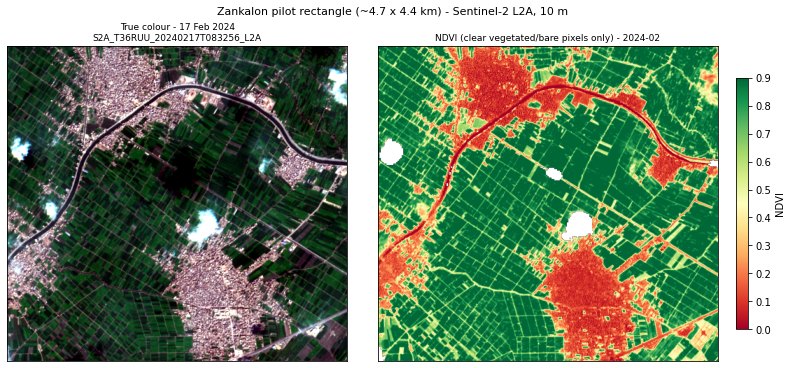

{'month': '2024-02', 'shown': True, 'scene': 'S2A_T36RUU_20240217T083256_L2A', 'acquired_utc': '2024-02-17', 'tile_cloud_%': 5.566329, 'image_pixels': 218700, 'clear_fraction': 0.987, 'median_ndvi_clear': 0.819, 'rejected_scenes': [], 'figure': 'results/explorer/sentinel2_2024-02.png'}


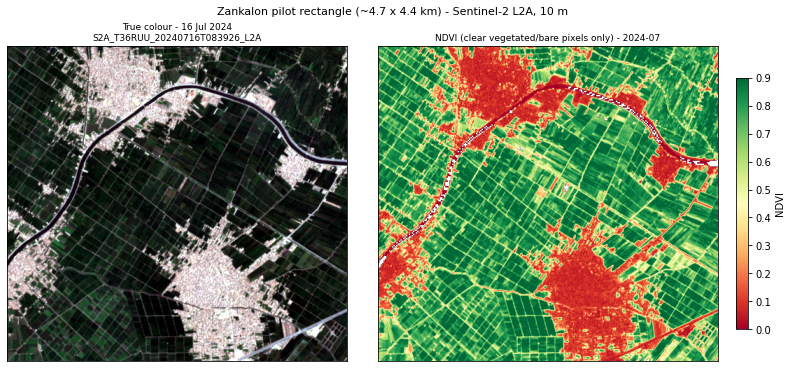

{'month': '2024-07', 'shown': True, 'scene': 'S2A_T36RUU_20240716T083926_L2A', 'acquired_utc': '2024-07-16', 'tile_cloud_%': 0.001257, 'image_pixels': 218700, 'clear_fraction': 0.993, 'median_ndvi_clear': 0.74, 'rejected_scenes': [], 'figure': 'results/explorer/sentinel2_2024-07.png'}


In [4]:
#@title 4. Show true-colour and NDVI images
def read_scene(item):
    """Read the four bands + scene classification for the rectangle and check them."""
    with rasterio.Env(**GDAL_OPTS):
        bands = {}
        for name in ["red", "green", "blue", "nir"]:
            sc, off = asset_scale_offset(item, name)
            bands[name] = to_reflectance(read_aoi(item.assets[name].href, BBOX), sc, off)
        shape = bands["red"].shape
        scl = read_aoi(item.assets["scl"].href, BBOX, out_shape=shape, resampling=Resampling.nearest)
    for k in ("green", "blue", "nir"):                        # make every band the same grid
        if bands[k].shape != shape:
            raise ValueError(f"{k} grid {bands[k].shape} differs from red {shape}")
    clear = np.isin(scl, CLEAR_SCL)
    has_data = np.isfinite(bands["red"]) & np.isfinite(bands["nir"])
    return bands, scl, clear & has_data, float(has_data.mean())

def show_month(month):
    candidates = scenes[scenes.month == month].sort_values(["tile_cloud_%", "acquired_utc"], kind="mergesort")
    if candidates.empty:
        print(f"{month}: no scene under the cloud limit - pick another month in SHOW_MONTHS."); return None
    rejected = []
    for sid in candidates.scene_id:                           # least cloudy tile first
        item = by_id[sid]
        bands, scl, clear, data_frac = read_scene(item)
        if clear.mean() >= MIN_CLEAR_FRACTION and data_frac >= MIN_CLEAR_FRACTION:
            break
        rejected.append({"scene": sid, "clear_fraction": round(float(clear.mean()), 3), "data_fraction": round(data_frac, 3)})
        print(f"  {sid}: only {clear.mean():.0%} of the rectangle is clear - trying the next scene")
    else:
        print(f"{month}: no scene has >= {MIN_CLEAR_FRACTION:.0%} clear pixels over the rectangle; month not shown.")
        return {"month": month, "shown": False, "rejected_scenes": rejected,
                "reason": f"no scene with >= {MIN_CLEAR_FRACTION:.0%} clear pixels inside the rectangle"}
    rgb = stretch(np.dstack([bands["red"], bands["green"], bands["blue"]]))
    v = ndvi(bands["nir"], bands["red"])
    v_clear = np.where(clear, v, np.nan)
    fig, axs = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
    axs[0].imshow(rgb); axs[0].set_title(f"True colour - {item.datetime:%d %b %Y}\n{item.id}", fontsize=9)
    im = axs[1].imshow(v_clear, cmap="RdYlGn", vmin=0, vmax=0.9)
    axs[1].set_title(f"NDVI (clear vegetated/bare pixels only) - {month}", fontsize=9)
    fig.colorbar(im, ax=axs[1], shrink=0.8, label="NDVI")
    for a in axs: a.set_xticks([]); a.set_yticks([])
    fig.suptitle("Zankalon pilot rectangle (~4.7 x 4.4 km) - Sentinel-2 L2A, 10 m", fontsize=11)
    path = OUT / f"sentinel2_{month}.png"; fig.savefig(path, dpi=150); plt.show()
    stats = {"month": month, "shown": True, "scene": item.id, "acquired_utc": f"{item.datetime:%Y-%m-%d}",
             "tile_cloud_%": float(item.properties.get("eo:cloud_cover", np.nan)), "image_pixels": int(v.size),
             "clear_fraction": round(float(clear.mean()), 3), "median_ndvi_clear": round(float(np.nanmedian(v_clear)), 3)
             if clear.any() else None, "rejected_scenes": rejected, "figure": str(path.relative_to(ROOT))}
    print(stats); return stats

if items:
    STATUS["sentinel2"]["displayed"] = []
    for m in SHOW_MONTHS:
        try:
            s = show_month(m)
            if s: STATUS["sentinel2"]["displayed"].append(s)
        except Exception as e:
            print(f"{m}: could not read pixels ({type(e).__name__}: {e}).")
            STATUS["sentinel2"]["displayed"].append({"month": m, "shown": False, "reason": f"{type(e).__name__}: {e}"})
            row = best[best.month == m]
            if not row.empty:
                print("Available asset names for this scene:", sorted(by_id[row.iloc[0].scene_id].assets)[:30])
else:
    print("Skipped: no Sentinel-2 scenes (see the search message in step 3).")

## 5. Is there open *hyperspectral* data over Zankalon?
**Tanager** (Planet) is a hyperspectral satellite: instead of Sentinel-2's 12 broad bands it records **426 narrow bands (380–2500 nm)**. Planet publishes a *sample* of scenes openly (CC BY 4.0), grouped in themed collections (agriculture, urban, natural lands, …).

This step reads the catalogue's scene footprints and measures how far each collection's nearest scene is from our rectangle. **Distance 0 = a scene overlaps Zankalon.** Nothing is assumed in advance: the answer is printed, and the next steps adapt to it.

In [5]:
#@title 5. Search Planet's open Tanager catalogue for scenes over Zankalon
from concurrent.futures import ThreadPoolExecutor
try:
    root = get_json(ROOT_CATALOG)
    COLLS = {}
    for link in [l for l in root["links"] if l.get("rel") == "child"]:
        try: COLLS[link.get("title", link["href"])] = get_json(link["href"])
        except Exception as e: print("Could not read collection", link.get("title"), "-", type(e).__name__)
except Exception as e:
    COLLS = {}
    STATUS["tanager"] = {"catalog": ROOT_CATALOG, "search_error": f"{type(e).__name__}: {e}"}
    print("SEARCH FAILED - Tanager catalogue unreachable:", type(e).__name__, e)
    print("The hyperspectral part will be skipped and the run record will say so. Re-run this cell when online.")

rows = []
for title, cj in COLLS.items():
    boxes = collection_boxes(cj)
    if not boxes: continue
    d = [bbox_distance_deg(BBOX, b) for b in boxes]
    span = cj.get("extent", {}).get("temporal", {}).get("interval", [[None, None]])[0]
    rows.append({"collection": cj.get("id", title), "scenes": len(boxes),
                 "nearest_scene_distance_deg": round(min(d), 2),
                 "covers_zankalon": bool(min(d) == 0),
                 "captured": f"{(span[0] or '')[:10]} to {(span[1] or '')[:10]}"})
cov = pd.DataFrame(rows, columns=["collection", "scenes", "nearest_scene_distance_deg", "covers_zankalon", "captured"])
cov = cov.sort_values("nearest_scene_distance_deg").reset_index(drop=True)
if COLLS:
    display(cov)
    ZANKALON_COVERED = bool(cov.covers_zankalon.any())
    print("Open Tanager scene overlapping Zankalon:", "YES" if ZANKALON_COVERED else "NO (about 1 degree = 100 km)")
    STATUS["tanager"] = {"catalog": ROOT_CATALOG, "collections_read": len(COLLS),
                         "zankalon_covered_by_open_sample": ZANKALON_COVERED, "collections": cov.to_dict("records")}
else:
    ZANKALON_COVERED = False
    print("No Tanager collections could be read, so coverage of Zankalon is UNKNOWN (not 'no').")

,collection,scenes,nearest_scene_distance_deg,covers_zankalon,captured
0,natural-lands,72,3.50,False,2024-09-25 to 2025-09-29
1,coastal-water-bodies,43,3.50,False,2025-02-23 to 2025-10-29
2,agriculture,44,6.98,False,2025-01-14 to 2025-09-29
3,GHG-plumes,8,9.85,False,2024-10-04 to 2025-07-03
4,urban,58,12.85,False,2024-10-25 to 2025-10-29
5,energy-mining,17,19.42,False,2024-09-25 to 2025-09-11
6,snow-ice,7,62.87,False,2025-04-11 to 2025-06-06
7,ROCX2025,16,109.43,False,2025-07-04 to 2025-10-29
8,fire,11,143.46,False,2024-12-15 to 2025-09-20


Open Tanager scene overlapping Zankalon: NO (about 1 degree = 100 km)


## 6. Pick the hyperspectral scene to examine
* If a Tanager scene **overlaps Zankalon**, it is chosen and treated as real Zankalon evidence.
* If not, the **nearest scene in the agriculture collection** is chosen as a **method demonstration**. It shows what hyperspectral data can reveal about crops, but **it is not Zankalon and is not used in the screening result**.

You can force a specific scene by setting `DEMO_ITEM_ID` in step 2.

In [6]:
#@title 6. Choose the hyperspectral scene
def fetch_items(urls, workers=8):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(get_json, urls))

def nearest_item(cj, aoi):
    """Nearest scene in a collection. Fast path pairs the footprint list with the item links
    and verifies it; if the verification fails, every item is read."""
    boxes, links = collection_boxes(cj), item_links(cj)
    if len(boxes) == len(links):
        k = int(np.argmin([bbox_distance_deg(aoi, b) for b in boxes]))
        it = get_json(links[k])
        if np.allclose(it["bbox"], boxes[k], atol=1e-3):
            return it, bbox_distance_deg(aoi, it["bbox"])
    allit = fetch_items(links)
    k = int(np.argmin([bbox_distance_deg(aoi, i["bbox"]) for i in allit]))
    return allit[k], bbox_distance_deg(aoi, allit[k]["bbox"])

DEMO = None
if RUN_HYPERSPECTRAL_DEMO and COLLS:
    try:
        if DEMO_ITEM_ID:
            src = next(c for c in COLLS.values() if any(DEMO_ITEM_ID in h for h in item_links(c)))
            DEMO = get_json(next(h for h in item_links(src) if DEMO_ITEM_ID in h)); dist = bbox_distance_deg(BBOX, DEMO["bbox"])
        elif ZANKALON_COVERED:
            cname = cov[cov.covers_zankalon].iloc[0].collection
            DEMO, dist = nearest_item(next(c for c in COLLS.values() if c.get("id") == cname), BBOX)
        else:
            DEMO, dist = nearest_item(next(c for c in COLLS.values() if c.get("id") == DEMO_COLLECTION), BBOX)
        IS_ZANKALON = bool(dist == 0)
        sr_key = pick_sr_asset(DEMO["assets"])
        DEMO_DATE = (DEMO.get("properties", {}).get("datetime") or "")[:10] or f"{DEMO['id'][:4]}-{DEMO['id'][4:6]}-{DEMO['id'][6:8]}"
        print("Selected scene:", DEMO["id"], "| acquired:", DEMO_DATE, "| footprint [W,S,E,N]:", [round(x, 2) for x in DEMO["bbox"]])
        print("Distance from Zankalon (deg):", round(dist, 2), "->", "OVERLAPS Zankalon" if IS_ZANKALON
              else "NOT Zankalon: method demonstration only")
        print("Reflectance asset:", sr_key)
        if sr_key is None:
            print("No surface-reflectance HDF5 asset recognised. Assets are:", sorted(DEMO["assets"]))
    except Exception as e:
        DEMO = None; STATUS["tanager"]["selection_error"] = f"{type(e).__name__}: {e}"
        print("SEARCH FAILED - could not select a scene:", type(e).__name__, e)
else:
    print("Hyperspectral demo skipped (RUN_HYPERSPECTRAL_DEMO=False or catalogue unavailable).")

Selected scene: 20250608_091605_90_4001 | acquired: 2025-06-08 | footprint [W,S,E,N]: [32.44, 37.51, 32.71, 37.69]
Distance from Zankalon (deg): 6.98 -> NOT Zankalon: method demonstration only
Reflectance asset: ortho_sr_hdf5


## 7. Download the hyperspectral scene
One scene is a single HDF5 file (typically **1–5 GB**). It is saved under `work/tanager_cache/`, which is **excluded from GitHub** by `.gitignore`. Re-running this cell does not download it again. Colab usually downloads this in a few minutes.

In [7]:
#@title 7. Download the HDF5 surface-reflectance file (large)
def download(url, dest, chunk=8 * 1024 * 1024):
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        print("Already downloaded:", dest.name, f"({dest.stat().st_size/1e9:.2f} GB)"); return dest
    part = dest.with_suffix(".part")
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0)); done = 0; next_mark = 0.1
        print(f"Downloading {dest.name}: {total/1e9:.2f} GB")
        with open(part, "wb") as f:
            for blk in r.iter_content(chunk):
                f.write(blk); done += len(blk)
                if total and done / total >= next_mark:
                    print(f"  {done/total:>4.0%}"); next_mark += 0.1
    part.rename(dest); return dest

H5_PATH = None
if DEMO is not None and sr_key:
    try:
        H5_PATH = download(DEMO["assets"][sr_key]["href"], CACHE / f"{DEMO['id']}_{sr_key}.h5")
    except Exception as e:
        STATUS["tanager"]["download_error"] = f"{type(e).__name__}: {e}"
        print("DOWNLOAD FAILED:", type(e).__name__, e, "- the rest of the notebook will skip the hyperspectral part.")

Already downloaded: 20250608_091605_90_4001_ortho_sr_hdf5.h5 (0.90 GB)


## 8. What does hyperspectral reveal? (spectra, red edge, comparison with Sentinel-2)
Four panels are produced from the downloaded scene:

* **A. Colour image** from three narrow bands (~640, 550, 460 nm).
* **B. Red-edge position (REP).** Healthy vegetation reflects almost no red light (chlorophyll absorbs it) but a lot of near-infrared; the wavelength where reflectance climbs fastest is the *red-edge position*. Stressed or sparse vegetation tends to shift it toward shorter wavelengths. **It is a descriptive indicator, not a measured chlorophyll or salinity value.**
* **C. Mean reflectance curves** of vegetated vs. bare pixels over 380–2500 nm. The grey bands are Sentinel-2's bands: notice how few samples Sentinel-2 has across the red edge. Wavelengths where the atmosphere absorbs water vapour (1350–1450 and 1800–1950 nm) are hidden.
* **D. Does Sentinel-2 see a related signal?** We *simulate* Sentinel-2 bands by averaging the narrow bands inside each band window (a box-car average, not the real spectral response), compute Sentinel-2's NDRE = (B8A − B05)/(B8A + B05), and plot it against the hyperspectral red-edge position pixel by pixel. **The correlation coefficient shown is a demonstration of agreement between two descriptive indicators on one scene. It is not an accuracy score, not a validation of the screening in notebook 04, and the red-edge position is quantised to the ~5 nm band spacing (the horizontal stripes).**

Quality rules: pixels flagged by the file's own cloud, cirrus and no-data masks are excluded, and only bands the file marks as usable (`good_wavelengths`; the water-vapour windows are excluded) enter the curves, the red-edge position and the simulated bands. Vegetated = simulated-Sentinel-2 NDVI above 0.5; bare = below 0.2 (demonstration thresholds, not calibrated).

Reading cube (426, 673, 776) (~0.9 GB in memory)


Bands: 368 usable of 426 (excluded: 1342-1438 nm, 1783-1967 nm)


Pixels: 359,001 valid (69%) | vegetated 47,976 | bare 180,240 | excluded by beta_cloud_mask/beta_cirrus_mask/nodata_pixels masks 163,247 (includes the empty corners of the tilted scene)


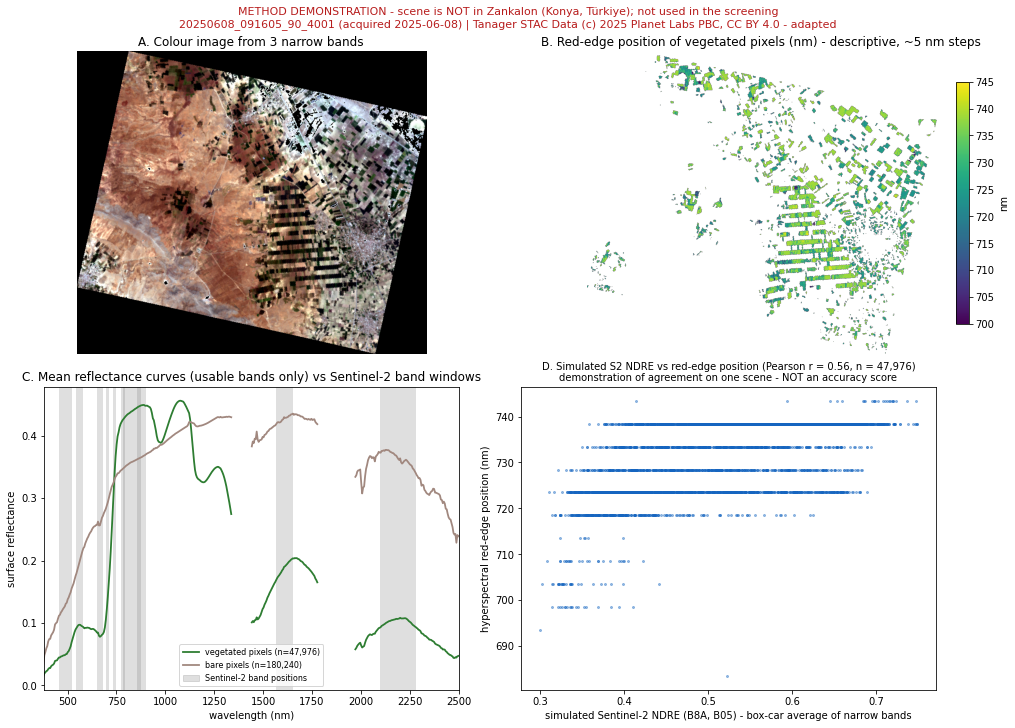

In [8]:
#@title 8. Analyse the hyperspectral scene and draw the figure
import h5py
def analyse(h5_path, item, sr_key, is_zankalon):
    wl = wavelengths_nm(item["assets"][sr_key])
    with h5py.File(h5_path, "r") as f:
        dsmap = find_datasets(f)
        name = dsmap.get("surface_reflectance") or next(
            (p for p in dsmap.values() if len(f[p].shape) == 3 and len(wl) in f[p].shape), None)
        if name is None: raise ValueError("No 3-D reflectance cube found. Datasets: " + ", ".join(sorted(dsmap)))
        D = f[name]; ba, ra, ca = cube_axes(D.shape, len(wl))
        gb = D.shape[ba] * D.shape[ra] * D.shape[ca] * 4 / 1e9
        print(f"Reading cube {D.shape} (~{gb:.1f} GB in memory)")
        if gb > 6: raise MemoryError("Cube too large for free Colab RAM; choose another scene.")
        good = usable_bands(D, wl)
        cube = read_band_range(D, ba, 0, len(wl))
        flags = np.zeros(cube.shape[1:], bool)
        masks_used = []
        for key in ("beta_cloud_mask", "beta_cirrus_mask", "nodata_pixels"):
            if key in dsmap:
                m = f[dsmap[key]][...]
                if m.shape == flags.shape: flags |= (m != 0); masks_used.append(key)
    if np.nanmedian(cube) > 2: cube = cube / 10000.0          # guard: stored as 0-10000 integers
    cube[:, flags] = np.nan
    cube[~good] = np.nan                                       # drop bands the file marks unusable (water vapour)
    print(f"Bands: {int(good.sum())} usable of {len(wl)} (excluded: {', '.join(f'{a:.0f}-{b:.0f} nm' for a, b in band_gaps(wl, good))})")
    sim = {k: simulate_band(wl, cube, *v, good=good) for k, v in S2_BANDS.items()}
    nd = norm_diff(sim["B08"], sim["B04"])
    veg, bare = np.nan_to_num(nd, nan=-9) > 0.5, (np.nan_to_num(nd, nan=9) < 0.2)
    valid_frac = float(np.isfinite(nd).mean())
    print(f"Pixels: {int(np.isfinite(nd).sum()):,} valid ({valid_frac:.0%}) | vegetated {int(veg.sum()):,} | bare {int(bare.sum()):,} | "
          f"excluded by {'/'.join(masks_used) or 'no'} masks {int(flags.sum()):,} (includes the empty corners of the tilted scene)")
    if valid_frac < 0.3: print("WARNING: less than 30% of the scene is usable (clouds or no-data) - try another DEMO_ITEM_ID.")
    if veg.sum() < 50: print("WARNING: very few vegetated pixels - this scene may not show crops; try another DEMO_ITEM_ID.")
    rep = red_edge_position(wl, cube, good)
    pick = lambda w: int(np.argmin(np.abs(wl - w)))
    rgb = stretch(np.dstack([cube[pick(640)], cube[pick(550)], cube[pick(460)]]))

    fig = plt.figure(figsize=(14, 10), constrained_layout=True)
    gs = fig.add_gridspec(2, 2)
    ax = fig.add_subplot(gs[0, 0]); ax.imshow(rgb); ax.set_title("A. Colour image from 3 narrow bands"); ax.axis("off")
    ax = fig.add_subplot(gs[0, 1]); im = ax.imshow(np.where(veg, rep, np.nan), cmap="viridis", vmin=700, vmax=745)
    ax.set_title("B. Red-edge position of vegetated pixels (nm) - descriptive, ~5 nm steps"); ax.axis("off"); fig.colorbar(im, ax=ax, shrink=0.8, label="nm")
    ax = fig.add_subplot(gs[1, 0])
    for mask, lab, col in ((veg, "vegetated pixels", "#2e7d32"), (bare, "bare pixels", "#a1887f")):
        if mask.sum() > 0:
            s = np.nanmean(cube[:, mask], axis=1).copy(); s[~good] = np.nan
            ax.plot(wl, s, color=col, lw=1.8, label=f"{lab} (n={int(mask.sum()):,})")
    for k, (c, w) in S2_BANDS.items():
        ax.axvspan(c - w / 2, c + w / 2, color="grey", alpha=0.25, lw=0)
    ax.axvspan(0, 0, color="grey", alpha=0.25, label="Sentinel-2 band positions")
    ax.set_xlim(380, 2500); ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("surface reflectance")
    ax.set_title("C. Mean reflectance curves (usable bands only) vs Sentinel-2 band windows"); ax.legend(fontsize=8)
    ax = fig.add_subplot(gs[1, 1])
    ndre = norm_diff(sim["B8A"], sim["B05"]); ok = veg & np.isfinite(ndre) & np.isfinite(rep)
    r = float("nan")
    if ok.sum() > 30:
        r = float(np.corrcoef(ndre[ok], rep[ok])[0, 1])
        idx = np.random.choice(np.flatnonzero(ok.ravel()), size=min(4000, int(ok.sum())), replace=False)
        ax.scatter(ndre.ravel()[idx], rep.ravel()[idx], s=4, alpha=0.4, color="#1565c0")
    ax.set_xlabel("simulated Sentinel-2 NDRE (B8A, B05) - box-car average of narrow bands"); ax.set_ylabel("hyperspectral red-edge position (nm)")
    ax.set_title(f"D. Simulated S2 NDRE vs red-edge position (Pearson r = {r:.2f}, n = {int(ok.sum()):,})\n"
                 "demonstration of agreement on one scene - NOT an accuracy score", fontsize=10)
    when = (item.get("properties", {}).get("datetime") or "")[:10] or f"{item['id'][:4]}-{item['id'][4:6]}-{item['id'][6:8]}"
    year = when[:4]
    banner = "Tanager scene overlapping Zankalon" if is_zankalon else "METHOD DEMONSTRATION - scene is NOT in Zankalon (Konya, Türkiye); not used in the screening"
    fig.suptitle(f"{banner}\n{item['id']} (acquired {when}) | Tanager STAC Data (c) {year} Planet Labs PBC, CC BY 4.0 - adapted",
                 fontsize=11, color="#b71c1c" if not is_zankalon else "black")
    path = OUT / "hyperspectral_demo.png"; fig.savefig(path, dpi=150); plt.show()
    return {"scene_id": item["id"], "acquired": when, "is_zankalon": bool(is_zankalon),
            "n_bands": int(len(wl)), "n_usable_bands": int(good.sum()), "quality_masks_applied": masks_used,
            "valid_pixels": int(np.isfinite(nd).sum()), "valid_fraction": round(valid_frac, 3), "vegetated_pixels": int(veg.sum()),
            "bare_pixels": int(bare.sum()), "red_edge_median_nm": float(np.nanmedian(rep[veg])) if veg.sum() else None,
            "s2_ndre_vs_red_edge_pearson_r": None if np.isnan(r) else round(r, 3),
            "pearson_r_meaning": "agreement between two descriptive indicators on one demonstration scene; not an accuracy or validation score",
            "figure": str(path.relative_to(ROOT)),
            "attribution": f"Tanager STAC Data, available at www.planet.com/data/stac (c) {year} Planet Labs PBC. All Rights Reserved. Adapted from the original (CC BY 4.0)."}

if H5_PATH is not None:
    try:
        STATUS["tanager"]["analysis"] = analyse(H5_PATH, DEMO, sr_key, IS_ZANKALON)
        STATUS["tanager"]["analysis"]["label"] = ("Zankalon hyperspectral evidence" if IS_ZANKALON
                                                  else "Method demonstration on a scene outside Zankalon")
    except Exception as e:
        STATUS["tanager"]["analysis_error"] = f"{type(e).__name__}: {e}"
        print("Hyperspectral analysis stopped:", type(e).__name__, e)
else:
    STATUS["tanager"].setdefault("analysis_error", "skipped: no hyperspectral file (see search/download messages above)")
    print("No hyperspectral file available - panels skipped. The Sentinel-2 part above is unaffected.")

## 9. Save the run record
This writes `results/explorer/explorer_status.json`: the exact scenes used, the Tanager coverage answer, and whether the hyperspectral panel is a Zankalon measurement or a demonstration. Quote **this file**, not memory, in the README and slides.

In [9]:
#@title 9. Save the run record (and optionally download the pictures)
import datetime
STATUS["run_utc"] = datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")
STATUS["note"] = ("Exploration notebook. The Sentinel-2 screening result is produced by notebook 04 and is not changed here. "
                  "A Tanager panel is Zankalon evidence only when analysis.is_zankalon is true.")
(OUT / "explorer_status.json").write_text(json.dumps(STATUS, indent=2))
print(json.dumps({k: v for k, v in STATUS.items() if k != "tanager"}, indent=2)[:1200])
print("Sentinel-2 scenes found:", STATUS["sentinel2"].get("scenes_found"), "| search error:", STATUS["sentinel2"].get("search_error", "none"))
print("Tanager covers Zankalon:", STATUS["tanager"].get("zankalon_covered_by_open_sample", "unknown (catalogue not read)"),
      "| analysis:", STATUS["tanager"].get("analysis", {}).get("label", STATUS["tanager"].get("analysis_error", "not run")))
print("Files saved:", sorted(p.name for p in OUT.iterdir()))
try:                                   # Colab only: one-click download of the pictures
    from google.colab import files
    import shutil; zip_base = str(OUT.parent / "explorer_results"); shutil.make_archive(zip_base, "zip", OUT); files.download(zip_base + ".zip")
except ImportError:
    pass

{
  "aoi_bbox_wgs84": [
    31.41,
    30.56,
    31.46,
    30.6
  ],
  "aoi_note": "Zankalon pilot rectangle; not an official farm or irrigation boundary",
  "sentinel2": {
    "catalog": "https://earth-search.aws.element84.com/v1",
    "collection": "sentinel-2-c1-l2a",
    "year": 2024,
    "scenes_found": 59,
    "months_with_scene": 12,
    "displayed": [
      {
        "month": "2024-02",
        "shown": true,
        "scene": "S2A_T36RUU_20240217T083256_L2A",
        "acquired_utc": "2024-02-17",
        "tile_cloud_%": 5.566329,
        "image_pixels": 218700,
        "clear_fraction": 0.987,
        "median_ndvi_clear": 0.819,
        "rejected_scenes": [],
        "figure": "results/explorer/sentinel2_2024-02.png"
      },
      {
        "month": "2024-07",
        "shown": true,
        "scene": "S2A_T36RUU_20240716T083926_L2A",
        "acquired_utc": "2024-07-16",
        "tile_cloud_%": 0.001257,
        "image_pixels": 218700,
        "clear_fraction": 0.993,
       

## What to do with the results
1. Download `explorer_results.zip` (starts automatically in Colab) and copy its files into the repository's **`results/explorer/`**.
2. Download this executed notebook (**File → Download → Download .ipynb**) and put it in `notebooks/` *with its outputs visible*.
3. In the README, embed `results/explorer/sentinel2_*.png` and `hyperspectral_demo.png`, and state what `explorer_status.json` says about Tanager coverage.
4. For **real Zankalon hyperspectral data**, continue with notebook 03 (EnMAP, free DLR account) and then notebook 04.

**Data credits.** Contains modified Copernicus Sentinel data (2024), accessed via Element 84 Earth Search. Tanager STAC Data, available at www.planet.com/data/stac © Planet Labs PBC, CC BY 4.0 — adapted.